# 第2回：相関分析（Correlation Analysis）

2つの変数（variable）が一緒にどう変化するかを調べるとき、散布図（scatter plot）を描き、関係を数値で要約する。その代表が相関係数（correlation coefficient）である。ただし相関係数は一種類ではない。変数の測定尺度（scale of measurement）や、測りたい関係に応じて方法を選ぶ必要がある。


[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rsimd/data-science-j26/blob/main/lesson-02.ipynb)

## 学習目標

- 共分散を標準化するとピアソンの積率相関係数になることを説明する。
- 散布図を確認してから係数を解釈する。
- データの尺度と分析目的に応じて指標を選ぶ。
- 指標ごとの前提と、相関から因果を結論づけられないことを説明する。

「相関係数」と呼ばれる指標も、すべて同じものを測るわけではない。級内相関係数は測定の信頼性・一致度、クラメールのVはカテゴリ間の関連の強さを表す。値の範囲や符号の意味も方法ごとに異なる。**計算の前に、変数の尺度と分析目的を確認する。**
Colabで実行する場合は、次のバッジから開く。日本語フォントは、続く準備セルで未導入の場合だけインストールする。

In [1]:
from importlib.util import find_spec
import subprocess
import sys

if find_spec("matplotlib_fontja") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib-fontja"])


## 1. 共分散（covariance）からピアソンの積率相関係数（Pearson product-moment correlation coefficient）へ

第1回で学んだ標本共分散（sample covariance）は

$$
s_{xy}=\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})
$$

である。共分散の単位は、$x$ と $y$ の単位を掛けたものになり、測定単位を変えると値も変わる。そこで共分散を各変数の標準偏差（standard deviation）で割る。

$$
r_{xy}=\frac{s_{xy}}{s_xs_y}
=\frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}
{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2}\sqrt{\sum_{i=1}^{n}(y_i-\bar{y})^2}}
$$

これが**ピアソンの積率相関係数（Pearson product-moment correlation coefficient）**である。値は $-1$ から $1$ の範囲をとる。正の値は右上がり、負の値は右下がりの直線的傾向を表す。絶対値が大きいほど直線的な関係が強い。$0$ に近くても、曲線など別の形の関係がないとは限らない。

### SciPy（Scientific Python）で相関係数を計算する

**SciPy**はPythonで科学技術計算を行うためのライブラリ（library）で、Pythonの配布パッケージ名（package name）も `scipy` である。その中の `scipy.stats` は統計処理をまとめたモジュール（module）で、相関係数を求める関数（function）として `pearsonr`、`spearmanr`、`kendalltau` などが用意されている。

このノートでは `from scipy import stats` と書いて `stats` モジュールを読み込み、`stats.pearsonr(x, y)` のように使う。関数は相関係数などを含む結果を返し、`.statistic` を付けると相関係数の値を取り出せる。ここでは係数の計算に注目し、返り値に含まれる $p$ 値（p-value）による仮説検定（hypothesis test）は別の回で扱う。

### 単位の違いを確かめる

標本共分散: 3.410
ピアソンの相関係数: 0.994
xを100倍したときの共分散: 341.000
xを100倍したときの相関係数: 0.994


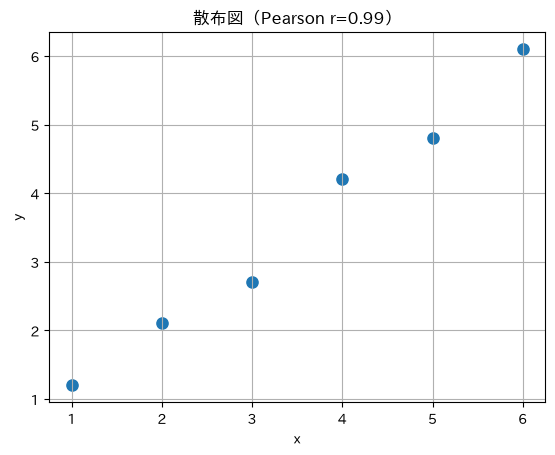

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib_fontja
from scipy import stats

plt.rcParams["axes.grid"] = True
rng = np.random.default_rng(2026)

x = np.array([1, 2, 3, 4, 5, 6], dtype=float)
y = np.array([1.2, 2.1, 2.7, 4.2, 4.8, 6.1], dtype=float)
r = stats.pearsonr(x, y).statistic
print(f"標本共分散: {np.cov(x, y, ddof=1)[0, 1]:.3f}")
print(f"ピアソンの相関係数: {r:.3f}")
print(f"xを100倍したときの共分散: {np.cov(100*x, y, ddof=1)[0, 1]:.3f}")
print(f"xを100倍したときの相関係数: {stats.pearsonr(100*x, y).statistic:.3f}")
plt.scatter(x, y, s=65)
plt.xlabel("x"); plt.ylabel("y"); plt.title(f"散布図（Pearson r={r:.2f}）")
plt.show()

## 2. 散布図（scatter plot）を先に見る

ピアソン係数は直線的な関係（linear relationship）を要約する。曲線、外れ値（outlier）、データのまとまりは係数だけからは分からない。以下の例では直線的・単調な曲線・U字型（U-shaped relationship）・外れ値の影響を比べる。

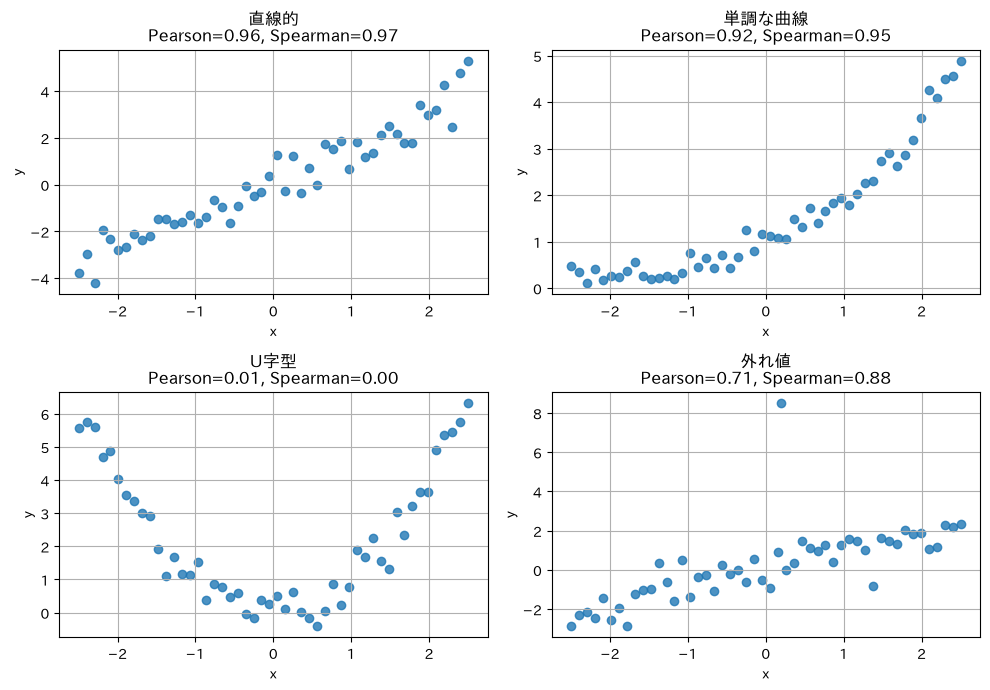

In [3]:
x_demo = np.linspace(-2.5, 2.5, 50)
y_linear = 1.3*x_demo + rng.normal(0, 0.65, len(x_demo))
y_monotone = np.exp(0.65*x_demo) + rng.normal(0, 0.18, len(x_demo))
y_u = x_demo**2 + rng.normal(0, 0.35, len(x_demo))
x_out = np.append(x_demo, 0.2)
y_out = np.append(0.9*x_demo + rng.normal(0, 0.55, len(x_demo)), 8.5)
examples = [(x_demo,y_linear,"直線的"),(x_demo,y_monotone,"単調な曲線"),(x_demo,y_u,"U字型"),(x_out,y_out,"外れ値")]
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax,(xx,yy,title) in zip(axes.flat,examples):
    pr=stats.pearsonr(xx,yy).statistic; sr=stats.spearmanr(xx,yy).statistic
    ax.scatter(xx,yy,alpha=.8); ax.set_title(f"{title}\nPearson={pr:.2f}, Spearman={sr:.2f}")
    ax.set_xlabel("x"); ax.set_ylabel("y")
plt.tight_layout(); plt.show()

U字型では $x$ と $y$ に明らかな関係があっても、ピアソン係数が $0$ に近くなることがある。散布図は係数を選ぶ前にも、得られた値を解釈するときにも見る。相関だけでは因果関係（causality）を決められない。第三の変数（third variable）や偶然の可能性も考える。


### 相関と因果関係を区別する（correlation vs causation）

**相関（correlation）**は、観察したデータで2つの変数が一緒に変化する傾向を表す。ピアソン相関では $r_{XY}=r_{YX}$ となり、どちらを先に書いても値は同じだ。一方、**因果関係（causal relationship）**は、「$X$ に働きかけて値を変えたとき、$Y$ がどう変わるか」という原因から結果への関係である。相関は対称だが、因果には向きがある。観察された相関だけでは、その向きも、因果効果の有無も決められない。

**擬似相関（spurious correlation）**とは、2つの変数に相関が見えても、一方が他方を直接引き起こしているとは言えない状況を指す。例えば、夏にはアイスクリームの売上と水難事故の件数がともに増え、正の相関が見られることがある。しかし、アイスクリームが水難事故を起こすわけではない。気温が高いとアイスクリームがよく売れ、海や川に行く人も増えるため、**共通原因（common cause）**である気温が両方に影響していると考えられる。

| 観察される相関 | 間違えやすい解釈 | 確認したいこと |
|---|---|---|
| アイスクリームの売上と水難事故が同時に増える | アイスクリームが事故を起こす | 気温や季節という共通原因（confounder）がないか |
| 運動量と体力に相関がある | 運動だけが体力を高めている | 体力のある人ほど運動しやすいという逆因果（reverse causality）もありうる |
| 時間とともに増える2系列に相関がある | 片方がもう片方を増やした | 両方が時間とともに増えただけではないか、偶然の相関（chance correlation）ではないか |

この例を簡単な矢印で表すと、共通原因の状況は

$$
Z \longrightarrow X, \qquad Z \longrightarrow Y
$$

である。$X$ と $Y$ は一緒に変化しても、$X$ が $Y$ を起こしたとは限らない。これに対して、因果の仮説は $X \longrightarrow Y$ と表せる。データに相関があることだけでは、共通原因の説明と因果の説明を区別できない。

**よくある読み違い**は、(1) 相関があるから原因と結果だと決める、(2) 原因と結果の向きを取り違える、(3) 第三の変数を統計的に調整すれば因果が証明されたと思う、の3つである。運動量と体力なら、運動が体力に影響する可能性だけでなく、体力が高い人ほど運動しやすい可能性や、年齢・健康状態が両方に影響する可能性も考える。

相関は因果関係を**証明しない**が、因果効果を調べる手がかりにはなる。因果を主張するには、原因が結果より先に起きたか、共通原因や対象の選ばれ方の影響がないかを検討し、可能なら無作為化比較試験（randomized controlled trial）など、因果を評価できる研究計画を用いる。観察データで第三の変数を統計的に調整するだけで、因果関係が自動的に証明されるわけではない。

#### 確認問題

アイスクリームの売上と水難事故の件数に正の相関が見られたとする。相関係数から言えることを1つ、言えないことを1つ書き、共通原因の候補を挙げる。さらに、アイスクリームの売上が事故を増やしたと結論づける前に、どのような追加情報や研究計画が必要かを説明する。


## 3. ピアソンの積率相関係数（Pearson product-moment correlation coefficient）

量的変数どうしの**直線的な関係**を要約する。計算前に散布図の直線性、外れ値、同じ対象から対になって測られた値かを確認する。係数を計算できることと、検定の前提が満たされることは別である。相関の検定は第8回で扱う。

## 4. 点双列相関係数（point-biserial correlation coefficient）

**点双列相関係数（point-biserial correlation coefficient）**は、連続変数（continuous variable）と二値変数（binary variable）との関係に用いる。例えば「教材を使った／使わない」と得点である。二値変数を $0,1$ で符号化（coding）すれば、点双列相関係数はその変数と連続値のピアソン相関に等しい。グループごとの連続値の平均を $\bar{y}_0,\bar{y}_1$、標本全体の標準偏差を $s_y$、各群の人数を $n_0,n_1$、全体の人数を $n$ とすると、次の式で表せる。

$$
r_{pb}=\frac{\bar{y}_1-\bar{y}_0}{s_y}\sqrt{\frac{n_0n_1}{n(n-1)}}
$$

平均との差が大きいほど、また2群の人数が極端に偏っていないほど、絶対値は大きくなりやすい。符号はどちらを $1$ としたかで反転する。この係数は二値変数と量的変数の記述的な関連（descriptive association）を表す。検定を行う場合は観測の独立性（independence of observations）など、方法に応じた条件も確認する。

点双列相関: 0.854
0/1符号化でのPearson: 0.854


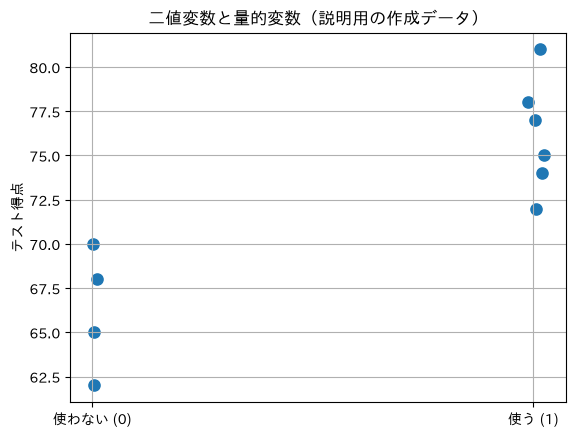

In [4]:
used = np.array([0,0,0,0,1,1,1,1,1,1])
score = np.array([62,68,70,65,72,75,78,74,81,77], dtype=float)
print(f"点双列相関: {stats.pointbiserialr(used, score).statistic:.3f}")
print(f"0/1符号化でのPearson: {stats.pearsonr(used, score).statistic:.3f}")
plt.scatter(used + rng.normal(0,.025,len(used)), score, s=65)
plt.xticks([0,1],["使わない (0)","使う (1)"]); plt.ylabel("テスト得点")
plt.title("二値変数と量的変数（説明用の作成データ）"); plt.show()

この作成データは実際の授業効果を表していない。相関から「教材が得点を上げた」と結論づけず、参加者の選ばれ方なども確認する。

## 5. 順位相関係数（rank correlation coefficient）：スピアマンとケンドール

測定値の差の大きさより、順序が重要なときは**順位相関係数（rank correlation coefficient）**を使う。

### スピアマンの順位相関係数（Spearman's rank correlation coefficient）

各変数を順位（rank）に置き換え、その順位どうしのピアソン相関を計算する。関係が直線でなくても、値が一貫して増加または減少する**単調な関係（monotonic relationship）**を捉える。同順位がない場合の式は

$$
\rho=1-\frac{6\sum_{i=1}^{n}d_i^2}{n(n^2-1)}
$$

であり、$d_i$ は対象 $i$ の2つの順位の差である。同順位（tied ranks）がある場合は順位に対するピアソン相関として計算する。

### ケンドールの順位相関係数（Kendall's rank correlation coefficient）

対象の組を比べ、両変数の順位が同じ向きの**一致対（concordant pair）**と、逆向きの**不一致対（discordant pair）**を数える。同順位がある場合は通常ケンドールのタウb（Kendall's tau-b; $\tau_b$）を用いる。

$$
\tau_b=\frac{P-Q}{\sqrt{(P+Q+T)(P+Q+U)}}
$$

$P,Q$ は一致対・不一致対、$T,U$ は片方の変数だけで同順位となる組の数である。スピアマンとケンドールはどちらも順位に基づくが、式と数値の意味は同じではない。

Pearson r:   0.929
Spearman ρ:  1.000
Kendall τ_b: 1.000


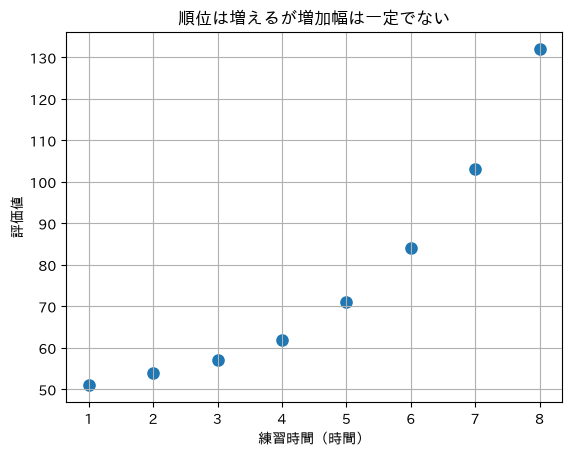

In [5]:
hours = np.arange(1, 9, dtype=float)
performance = np.array([51,54,57,62,71,84,103,132], dtype=float)
print(f"Pearson r:   {stats.pearsonr(hours, performance).statistic:.3f}")
print(f"Spearman ρ:  {stats.spearmanr(hours, performance).statistic:.3f}")
print(f"Kendall τ_b: {stats.kendalltau(hours, performance).statistic:.3f}")
plt.scatter(hours, performance, s=65); plt.xlabel("練習時間（時間）"); plt.ylabel("評価値")
plt.title("順位は増えるが増加幅は一定でない"); plt.show()

## 6. 偏相関係数（partial correlation coefficient）

**偏相関係数（partial correlation coefficient）**は、別の変数 $Z$ の線形な影響を $X,Y$ から取り除き、残った線形関係を調べる。$X$ と $Y$ をそれぞれ $Z$ で線形回帰（linear regression）した残差（residual）を $e_X,e_Y$ とすると、

$$
r_{XY\cdot Z}=\operatorname{corr}(e_X,e_Y)
=\frac{r_{XY}-r_{XZ}r_{YZ}}{\sqrt{(1-r_{XZ}^2)(1-r_{YZ}^2)}}
$$

である。測定していない要因を除くものでも、因果関係を証明するものでもない。残差どうしの相関としての説明は[SAS/STATガイド](https://support.sas.com/documentation/cdl/en/procstat/66703/HTML/default/procstat_corr_details09.htm)を参照。

調整前 Pearson r: 0.612
zを調整した偏相関: -0.132


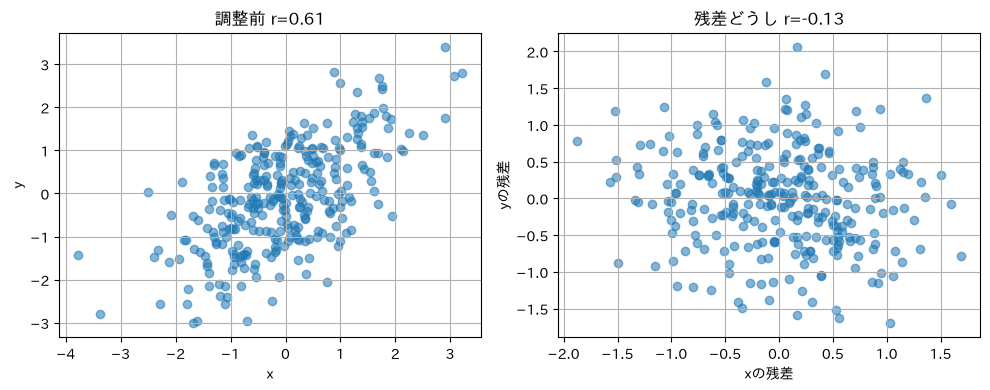

In [6]:
rng_p = np.random.default_rng(42)
z = rng_p.normal(size=300)
xp = .9*z + rng_p.normal(scale=.65,size=300)
yp = 1.1*z + rng_p.normal(scale=.65,size=300)
zd = np.column_stack([np.ones_like(z), z])
ex = xp - zd @ np.linalg.lstsq(zd, xp, rcond=None)[0]
ey = yp - zd @ np.linalg.lstsq(zd, yp, rcond=None)[0]
raw = stats.pearsonr(xp,yp).statistic
partial = stats.pearsonr(ex,ey).statistic
print(f"調整前 Pearson r: {raw:.3f}")
print(f"zを調整した偏相関: {partial:.3f}")
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].scatter(xp,yp,alpha=.55); axes[0].set_title(f"調整前 r={raw:.2f}")
axes[0].set_xlabel("x"); axes[0].set_ylabel("y")
axes[1].scatter(ex,ey,alpha=.55); axes[1].set_title(f"残差どうし r={partial:.2f}")
axes[1].set_xlabel("xの残差"); axes[1].set_ylabel("yの残差")
plt.tight_layout(); plt.show()

## 7. カテゴリ変数（categorical variable）の関連：ファイ係数とクラメールのV

**名義尺度（nominal scale）**とは、データを種類や名前で分類する尺度である。たとえば「補習に参加／不参加」「試験に合格／不合格」「花の品種」のようなカテゴリがあり、カテゴリ同士に大小や順番はない。カテゴリに数字を割り当てても、それは区別のための番号であり、数の大小を意味しない。

**分割表（contingency table）**は、2つのカテゴリ項目について、それぞれの組み合わせに当てはまるデータの個数（frequency）を数えた表である。行に「補習に参加したか」、列に「試験に合格したか」を置くと、各マスには両方の条件を満たす学生数が入る。次は説明用に作った80人分の例だ。

|  | 合格 | 不合格 | 合計 |
|---|---:|---:|---:|
| 補習に参加 | 30 | 10 | 40 |
| 補習に不参加 | 12 | 28 | 40 |
| 合計 | 42 | 38 | 80 |

これは説明用の架空データであり、補習の効果を示す実測結果ではない。この $2\times2$ 表から、二値カテゴリ間の関連をファイ係数で要約できる。

### ファイ係数（phi coefficient）

**ファイ係数**は2つの二値変数からなる $2\times2$ 分割表に用いる。表を $\begin{pmatrix}a&b\\c&d\end{pmatrix}$ と書くと、

$$
\phi=\frac{ad-bc}{\sqrt{(a+b)(c+d)(a+c)(b+d)}}
$$

である。符号は行・列カテゴリの符号化に依存する。二値変数を $0,1$ で符号化したピアソン相関と等しい。

### クラメールのV（Cramér's V）

**クラメールのV**は行・列が2を超える分割表にも使う。例えば「学科」と「合否」の関係なら、3学科×2結果の表を作れる。

$$
V=\sqrt{\frac{\chi^2}{n\min(r-1,c-1)}}
$$

$r,c$ は行数・列数、$n$ は標本数、$\chi^2$ は独立性（independence）を調べるカイ二乗統計量（chi-square statistic）である。値は $0$ から $1$ で関連の強さを表すが、方向は表さない。$2\times2$ 表では $V=|\phi|$ となる。


In [7]:
counts = np.array([[30,10],[12,28]])
a,b=counts[0]; c,d=counts[1]
phi=(a*d-b*c)/np.sqrt((a+b)*(c+d)*(a+c)*(b+d))
bx=np.repeat([0,0,1,1],[a,b,c,d]); by=np.repeat([0,1,0,1],[a,b,c,d])
print("補習参加 × 合否の分割表（行:参加/不参加、列:合格/不合格）:")
print("              合格  不合格")
print(f"参加          {a:>3}   {b:>3}")
print(f"不参加        {c:>3}   {d:>3}")
print(f"ファイ係数: {phi:.3f}; 0/1 Pearson: {stats.pearsonr(bx,by).statistic:.3f}")

counts_3x2=np.array([[22,8],[15,15],[7,23]])
chi2=stats.chi2_contingency(counts_3x2, correction=False).statistic
v=np.sqrt(chi2/(counts_3x2.sum()*min(counts_3x2.shape[0]-1,counts_3x2.shape[1]-1)))
print("\n学科 × 合否の分割表（説明用の架空データ）:")
print("          合格  不合格")
for label,row in zip(["情報系","機械系","電気系"],counts_3x2):
    print(f"{label:6}    {row[0]:>3}   {row[1]:>3}")
print(f"カイ二乗統計量: {chi2:.3f}; クラメールのV: {v:.3f}")


補習参加 × 合否の分割表（行:参加/不参加、列:合格/不合格）:
              合格  不合格
参加           30    10
不参加         12    28
ファイ係数: 0.451; 0/1 Pearson: 0.451

学科 × 合否の分割表（説明用の架空データ）:
          合格  不合格
情報系        22     8
機械系        15    15
電気系         7    23
カイ二乗統計量: 15.030; クラメールのV: 0.409


ファイ係数やクラメールのVは、連続量どうしの直線関係を表すピアソン係数とは別の関連指標である。分割表のセル数が少ない場合の検定法は、第7回「度数に関する検定」で扱う。

## 8. ポリコリック相関係数（polychoric correlation coefficient）

**ポリコリック相関係数（polychoric correlation coefficient）**は、順序尺度（ordinal scale）の背後にある2つの潜在連続変数（latent continuous variables）の相関を推定する指標である。たとえば、アンケートの「満足度」と「信頼度」の回答を考える。回答者の中には、直接は測れない連続的な満足度 $X^*$ と信頼度 $Y^*$ があり、それぞれの値が閾値（threshold; cutpoint）で区切られて「1〜4」の回答として観測される、と仮定する。

### 回答カテゴリが生まれる仕組みの例

説明用に、潜在変数を標準化し、次の境界値で4段階の回答に変換するとする。

$$
X=\begin{cases}
1 & X^*\le -0.8,\\
2 & -0.8<X^*\le 0,\\
3 & 0<X^*\le 0.8,\\
4 & X^*>0.8.
\end{cases}
$$

$Y$ も同じように $Y^*$ の境界値で作る。ここで $X^*$ と $Y^*$ は、相関 $\rho$ をもつ二変量標準正規分布（bivariate standard normal distribution）に従うと仮定する。

$$
\begin{pmatrix}X^*\\Y^*\end{pmatrix}
\sim \mathcal{N}_2\left(
\begin{pmatrix}0\\0\end{pmatrix},
\begin{pmatrix}1&\rho\\\rho&1\end{pmatrix}
\right)
$$

実際の調査では境界値は既知とは限らず、カテゴリごとの人数から推定する。

潜在変数がそれぞれ第 $i$ カテゴリ、第 $j$ カテゴリに入る確率は、潜在分布の二変量累積分布関数（bivariate cumulative distribution function）$\Phi_2$ を用いて次のように表せる。

$$
P(X=i,Y=j)=\Phi_2(\tau_i,\kappa_j;\rho)-\Phi_2(\tau_{i-1},\kappa_j;\rho)-\Phi_2(\tau_i,\kappa_{j-1};\rho)+\Phi_2(\tau_{i-1},\kappa_{j-1};\rho)
$$

ここで $\Phi_2(a,b;\rho)=P(X^*\le a,Y^*\le b)$ は相関 $\rho$ の二変量標準正規分布の累積分布関数、$\tau$ と $\kappa$ は $X^*$ と $Y^*$ のカテゴリ境界で、端は $-\infty,+\infty$ とする。実データでは、観測された分割表（contingency table）の各セルの人数にこの確率がよく合うように境界値と $\rho$ を推定（estimation）する。このとき得られる $\rho$ がポリコリック相関係数である。

したがって、回答番号 $1,2,3,4$ をそのまま数値とみなして計算するPearson相関とは異なる。ポリコリック相関は「背後に二変量正規分布の潜在変数がある」という仮定に基づく推定値であり、仮定が妥当でなければ解釈にも注意が必要である。[Kampen & Weeren (2017)](https://link.springer.com/article/10.1007/s11135-016-0378-2) は、この仮定と適用上の注意を検討している。

次のシミュレーションでは、潜在相関を $0.7$ に設定して連続データを生成し、境界値で4段階に区切る。生成時の潜在相関と、カテゴリ番号にPearson相関を適用した値を比べる。これは仕組みを示す例で、ポリコリック相関をデータから推定するコードではない。

生成時の潜在相関: 0.700
カテゴリ番号の Pearson r: 0.621


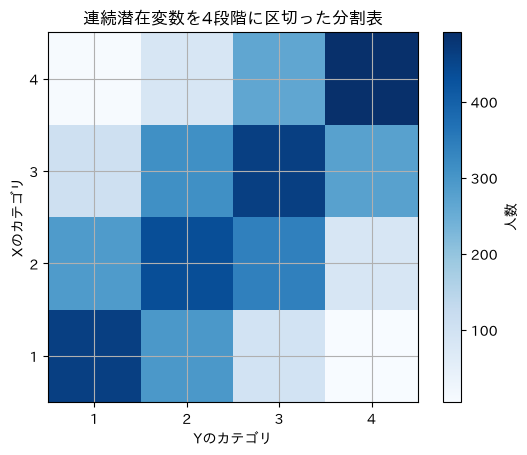

In [8]:
rho_latent=.7
latent=np.random.default_rng(2026).multivariate_normal([0,0],[[1,rho_latent],[rho_latent,1]],size=4000)
thresh=[-.8,0,.8]
ord_x=np.digitize(latent[:,0],thresh)+1; ord_y=np.digitize(latent[:,1],thresh)+1
ct=np.histogram2d(ord_x,ord_y,bins=[4,4],range=[[.5,4.5],[.5,4.5]])[0].astype(int)
print(f"生成時の潜在相関: {rho_latent:.3f}")
print(f"カテゴリ番号の Pearson r: {stats.pearsonr(ord_x,ord_y).statistic:.3f}")
plt.imshow(ct,origin="lower",cmap="Blues"); plt.colorbar(label="人数")
plt.xticks(range(4),["1","2","3","4"]); plt.yticks(range(4),["1","2","3","4"])
plt.xlabel("Yのカテゴリ"); plt.ylabel("Xのカテゴリ"); plt.title("連続潜在変数を4段階に区切った分割表"); plt.show()

## 9. 級内相関係数（intraclass correlation coefficient; ICC）

級内相関係数（intraclass correlation coefficient; ICC）は、同じ対象を複数の測定者が評価する場合や繰り返し測定する場合の信頼性（reliability）・一致度（agreement）を調べる。ICCは単一の公式ではない。測定者を固定効果（fixed effect）とみるかランダム効果（random effect）とみるか、単一測定（single measurement）と平均測定（average measurement）のどちらを評価するか、一貫性（consistency）と絶対一致（absolute agreement）のどちらを見るかを選ぶ。

以下の式と例は、各対象を同じ $k$ 人の測定者が評価した、欠測のない均衡データを前提とする。対象数を $n$、測定者数を $k$、対象間平均平方（mean square for rows）$MS_R$、測定者間平均平方（mean square for columns）$MS_C$、残差平均平方（mean square error）$MS_E$ として、二元配置ランダム効果モデル（two-way random-effects model）・絶対一致・単一測定の形（表記例 ICC(2,1) または ICC(A,1)）を示す。

$$
ICC(A,1)=\frac{MS_R-MS_E}{MS_R+(k-1)MS_E+\frac{k}{n}(MS_C-MS_E)}
$$

表記は文献によって異なるため、略号だけでなくモデルと一致の定義を報告する。絶対一致では、ある測定者が常に高い点を付けるような系統差も考慮する。[Koo & Li (2016)](https://pmc.ncbi.nlm.nih.gov/articles/4913118/) を参照。

測定者1と3の Pearson r: 0.990
絶対一致の ICC(A,1): 0.664
測定者ごとの平均: [39.7 40.6 47.7]


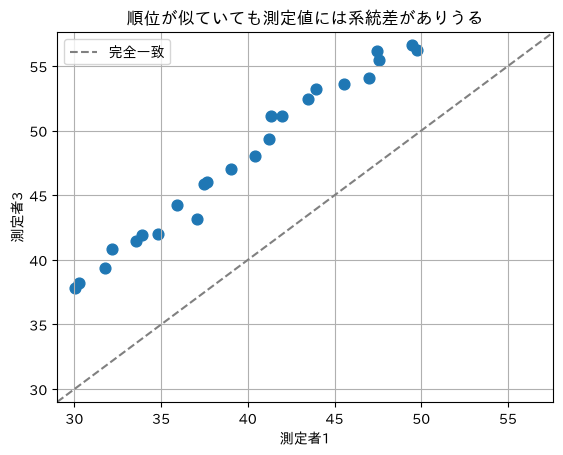

In [9]:
def icc_a1(ratings):
    """Two-way random, absolute-agreement, single-measure ICC(A,1)."""
    ratings=np.asarray(ratings,dtype=float); n,k=ratings.shape
    grand=ratings.mean(); means_subject=ratings.mean(axis=1); means_rater=ratings.mean(axis=0)
    ms_subject=k*np.sum((means_subject-grand)**2)/(n-1)
    ms_rater=n*np.sum((means_rater-grand)**2)/(k-1)
    ss_total=np.sum((ratings-grand)**2)
    ss_subject=k*np.sum((means_subject-grand)**2)
    ss_rater=n*np.sum((means_rater-grand)**2)
    ms_error=(ss_total-ss_subject-ss_rater)/((n-1)*(k-1))
    return (ms_subject-ms_error)/(ms_subject+(k-1)*ms_error+k*(ms_rater-ms_error)/n)

rng_i=np.random.default_rng(7); subject=np.linspace(30,50,24)
ratings=subject[:,None]+np.array([0.,.5,8.])[None,:]+rng_i.normal(0,.7,size=(24,3))
r13=stats.pearsonr(ratings[:,0],ratings[:,2]).statistic
icc=icc_a1(ratings)
print(f"測定者1と3の Pearson r: {r13:.3f}")
print(f"絶対一致の ICC(A,1): {icc:.3f}")
print(f"測定者ごとの平均: {ratings.mean(axis=0).round(1)}")
lims=[ratings.min()-1,ratings.max()+1]
plt.scatter(ratings[:,0],ratings[:,2],s=60); plt.plot(lims,lims,"--",color="gray",label="完全一致")
plt.xlim(lims); plt.ylim(lims); plt.xlabel("測定者1"); plt.ylabel("測定者3")
plt.title("順位が似ていても測定値には系統差がありうる"); plt.legend(); plt.show()

測定者1と3は対象を似た順に並べるため、ピアソン相関は高くなりうる。一方、測定者3が一貫して高く採点しているので、絶対一致のICCはそれを信頼性の低下として扱う。ピアソン相関だけで測定者間の一致を評価しない。

## 10. 目的に応じて指標を選ぶ

| データと目的 | 指標の候補 | 要約するもの |
|---|---|---|
| 量的変数どうしの直線的関係 | ピアソン（Pearson） | 直線的な向きと強さ |
| 量的変数と二値変数 | 点双列（point-biserial） | 連続値と二値群との関係 |
| 順位・順序尺度、単調な関係 | スピアマン（Spearman）／ケンドール（Kendall） | 順位の対応 |
| 他変数の線形な影響を調整 | 偏相関（partial correlation） | 残差どうしの関係 |
| 2つの二値カテゴリ（$2\times2$表） | ファイ係数（phi） | 関連の強さと符号化に応じた方向 |
| 名義カテゴリどうし | クラメールのV（Cramér's V） | カテゴリ間の関連の強さ |
| 潜在正規変数を仮定する順序カテゴリ | ポリコリック（polychoric） | 潜在連続変数どうしの相関 |
| 同じ対象の反復測定・評価者間信頼性 | 級内相関係数（intraclass correlation coefficient; ICC） | 選択したモデルでの一貫性または絶対一致 |

選ぶときは「データは何尺度か」「どんな関係を知りたいか」「方法の前提は妥当か」を順に確認する。


## 11. 相関係数の大きさを読む

相関係数 $r$（順位相関なら $\rho$ や $\tau$）の符号は関係の向きを、絶対値 $|r|$ は関係の強さを表す。母集団のPearson相関が $0$ なら線形な相関がなく、順位相関が $0$ なら、その順位相関係数では単調な傾向を捉えていないという意味だ。ただし標本から得る値が厳密に $0$ になるとは限らないため、実際には $0$ に近い小さな値を「ほぼ無相関」と呼ぶ目安を使う。次の表はSchoberらが示した**目安**を、正負の向きに分けて並べたものだ。

| 呼び方 | 相関係数の範囲 | 読み方 |
|---|---:|---|
| 強い正の相関（strong positive correlation） | $0.70 \le r < 0.90$ | 一方が大きいとき他方も大きい傾向が強い |
| 非常に強い正の相関（very strong positive correlation） | $0.90 \le r \le 1.00$ | 正の関係が非常に強い。$r=1$ は完全な正の直線関係 |
| 中程度の正の相関（moderate positive correlation） | $0.40 \le r < 0.70$ | 正の関係が中程度 |
| 弱い正の相関（weak positive correlation） | $0.10 \le r < 0.40$ | 正の関係は弱い |
| ほぼ無相関（negligible correlation） | $-0.10 < r < 0.10$ | 線形（Spearmanでは単調）な関係がほとんど見られない |
| 弱い負の相関（weak negative correlation） | $-0.40 < r \le -0.10$ | 一方が大きいとき他方は小さい傾向が弱い |
| 中程度の負の相関（moderate negative correlation） | $-0.70 < r \le -0.40$ | 負の関係が中程度 |
| 強い負の相関（strong negative correlation） | $-0.90 < r \le -0.70$ | 負の関係が強い |
| 非常に強い負の相関（very strong negative correlation） | $-1.00 \le r \le -0.90$ | 負の関係が非常に強い。$r=-1$ は完全な負の直線関係 |

Schoberらの目安では、$|r|<0.10$ は「ほぼ無相関」、$0.10$–$0.39$ は「弱い」、$0.40$–$0.69$ は「中程度」、$0.70$–$0.89$ は「強い」、$0.90$–$1.00$ は「非常に強い」と分類する。ここではそれぞれ正負に分けた。文献によって境界は異なり、分野や測定の信頼性、データの範囲によっても解釈は変わるため、絶対的な判定規則ではない。Schoberら自身も、境界値を機械的に適用することへの注意を述べている。

また、標本の相関係数が $0$ に近くても「変数に関係がない」とは限らない。曲線状の関係はPearson相関に現れにくく、相関係数の大きさだけでは統計的有意性や因果関係も判断できない。散布図、標本数、研究分野で意味のある差を合わせて考える。

## 12. Irisデータで相関を計算する

Iris（アヤメ）データセットは、150個体についてがく片と花弁の長さ・幅を測定し、3種を記録した有名なデータである。ここでは4つの量的特徴量どうしのPearson相関とSpearman順位相関を計算する。全種をまとめた結果に加え、花弁の長さと幅の関係を種別に分けて散布図で確認する。全体の相関は種間の違いも反映するため、種内の関係と同じとは限らない。



標本数: 150、特徴量数: 4、品種数: 3

Pearson相関係数
                   がく片の長さ     がく片の幅     花弁の長さ      花弁の幅
  がく片の長さ      1.00     -0.12      0.87      0.82
   がく片の幅     -0.12      1.00     -0.43     -0.37
   花弁の長さ      0.87     -0.43      1.00      0.96
    花弁の幅      0.82     -0.37      0.96      1.00

Spearman順位相関係数
                   がく片の長さ     がく片の幅     花弁の長さ      花弁の幅
  がく片の長さ      1.00     -0.17      0.88      0.83
   がく片の幅     -0.17      1.00     -0.31     -0.29
   花弁の長さ      0.88     -0.31      1.00      0.94
    花弁の幅      0.83     -0.29      0.94      1.00

花弁の長さと幅のPearson相関
全品種をまとめた相関: r = 0.963
    setosa: r = 0.332 (n=50)
versicolor: r = 0.787 (n=50)
 virginica: r = 0.322 (n=50)


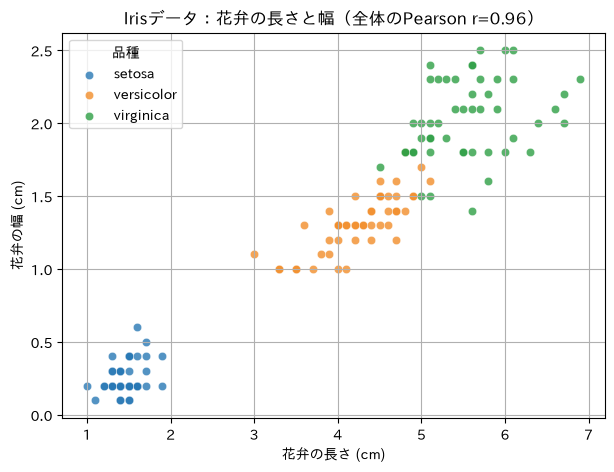


Irisデータの分割表：品種 × 花弁の幅
品種            1 cm以下     1 cm超
      setosa        50         0
  versicolor         7        43
   virginica         0        50
カイ二乗統計量: 124.448; クラメールのV: 0.911


In [10]:
from sklearn.datasets import load_iris

iris = load_iris()
X_iris = iris.data
feature_names = ["がく片の長さ", "がく片の幅", "花弁の長さ", "花弁の幅"]

pearson_matrix = np.corrcoef(X_iris, rowvar=False)
spearman_matrix = stats.spearmanr(X_iris, axis=0).statistic

def print_correlation_matrix(title, matrix, names):
    """Print a labeled correlation matrix rounded to two decimal places."""
    print(title)
    print("                 " + "  ".join(f"{name:>8}" for name in names))
    for name, row in zip(names, matrix):
        print(f"{name:>8}  " + "  ".join(f"{value:8.2f}" for value in row))

print(f"標本数: {len(X_iris)}、特徴量数: {X_iris.shape[1]}、品種数: {len(iris.target_names)}")
print_correlation_matrix("\nPearson相関係数", pearson_matrix, feature_names)
print_correlation_matrix("\nSpearman順位相関係数", spearman_matrix, feature_names)

# 花弁の長さと幅について、全体と品種別のPearson相関を比較する。
petal_length = X_iris[:, 2]
petal_width = X_iris[:, 3]
print("\n花弁の長さと幅のPearson相関")
print(f"全品種をまとめた相関: r = {stats.pearsonr(petal_length, petal_width).statistic:.3f}")
for class_id, species in enumerate(iris.target_names):
    mask = iris.target == class_id
    r_species = stats.pearsonr(petal_length[mask], petal_width[mask]).statistic
    print(f"{species:>10}: r = {r_species:.3f} (n={mask.sum()})")

fig, ax = plt.subplots(figsize=(7, 5))
colors = ["#2878B5", "#F28E2B", "#2E9F45"]
for class_id, species in enumerate(iris.target_names):
    mask = iris.target == class_id
    ax.scatter(petal_length[mask], petal_width[mask], label=species,
               color=colors[class_id], alpha=0.8, edgecolor="white", linewidth=0.35)
ax.set_xlabel("花弁の長さ (cm)")
ax.set_ylabel("花弁の幅 (cm)")
ax.set_title(f"Irisデータ：花弁の長さと幅（全体のPearson r={stats.pearsonr(petal_length, petal_width).statistic:.2f}）")
ax.legend(title="品種")
plt.show()

# 実データから作った3×2分割表：品種 × 花弁の幅（1 cm以下 / 1 cm超）。
# 連続値をカテゴリ化すると情報が失われるため、これは相関係数の代わりではなく、分割表指標の例。
width_labels = ["1 cm以下", "1 cm超"]
contingency = np.zeros((len(iris.target_names), 2), dtype=int)
for class_id in range(len(iris.target_names)):
    mask = iris.target == class_id
    contingency[class_id, 0] = np.sum(X_iris[mask, 3] <= 1.0)
    contingency[class_id, 1] = np.sum(X_iris[mask, 3] > 1.0)
chi2_iris = stats.chi2_contingency(contingency, correction=False).statistic
cramers_v_iris = np.sqrt(chi2_iris / (contingency.sum() * min(contingency.shape[0]-1, contingency.shape[1]-1)))
print("\nIrisデータの分割表：品種 × 花弁の幅")
print("品種          " + "  ".join(f"{label:>8}" for label in width_labels))
for species, row in zip(iris.target_names, contingency):
    print(f"{species:>12}  " + "  ".join(f"{count:8d}" for count in row))
print(f"カイ二乗統計量: {chi2_iris:.3f}; クラメールのV: {cramers_v_iris:.3f}")


## 演習
### 1. 直線関係か、単調関係か

次のデータの散布図を描き、ピアソン、スピアマン、ケンドールの係数を比べる。違いを散布図から説明する。


In [11]:
x_ex=np.arange(1,9,dtype=float)
y_ex=np.array([2.0,2.4,3.0,4.1,5.8,8.1,11.3,15.2])
# ここに散布図と3種類の係数を計算するコードを書く

### 2. 外れ値を加える

演習1のデータに、$x$ は中ほどだが $y$ は非常に大きい点を追加する。散布図と3種類の係数がどう変わったかを説明する。

In [12]:
# ここに外れ値を追加し、散布図と係数を比べるコードを書く

### 3. 指標を選ぶ

次の場面で候補となる指標と、選ぶ理由・必要な仮定を説明する。

1. 2つの二値項目の関連を $2\times2$ 表から調べる。
2. 3人の評価者が同じ作品に付けた点数の絶対的な一致を評価する。
3. 5段階アンケート2項目の背後にある連続特性の相関を推定する。
4. 第三の量の線形な影響を調整した後の2測定値の関係を調べる。

### 4. トピック一貫性：人手評価と自動指標の相関

トピックモデルが出力した単語群（topic）について、人が「意味のまとまりがあるか」を評価する人手評価（human evaluation）と、単語の共起などから計算する自動一貫性指標（automatic coherence metric）を比べる研究がある。例えば、自動指標の一つに $C_v$ がある。人手評価との相関を調べることで、自動指標が人の判断とどの程度連動するかを検討できる。[Newman et al. (2010)](https://aclanthology.org/N10-1012/) は人手によるトピック評価と自動スコアを比較し、[Röder et al. (2015)](https://doi.org/10.1145/2684822.2685324) は複数のトピック一貫性指標を人手評価との相関で比較している。

次の表は**実際の研究データではなく、計算練習用に作った架空データ**である。12個のトピックを10人が1〜5点で評価した平均点と、各トピックの $C_v$ スコアを並べた。ここでは $C_v$ が大きいほど自動指標上の一貫性が高い向きとしている。

| トピック | 人手評価の平均（1〜5点） | 自動指標 $C_v$ |
|---|---:|---:|
| T01 | 4.7 | 0.64 |
| T02 | 4.1 | 0.58 |
| T03 | 4.5 | 0.52 |
| T04 | 3.8 | 0.57 |
| T05 | 4.0 | 0.45 |
| T06 | 3.2 | 0.49 |
| T07 | 3.5 | 0.38 |
| T08 | 2.7 | 0.42 |
| T09 | 3.0 | 0.31 |
| T10 | 2.3 | 0.35 |
| T11 | 1.9 | 0.22 |
| T12 | 2.8 | 0.28 |

1. 人手評価を横軸、自動指標を縦軸にした散布図を描き、Pearson相関係数とSpearmanの順位相関係数を計算する。
2. 2つの係数の値を比べ、どちらがこのデータの関係をよく要約するか説明する。
3. 相関が高かったとして、何が言えて何がまだ言えないかを説明する。自動指標と人手評価は異なる尺度なので、相関が高くても数値の一致（agreement）や妥当性（validity）が証明されたことにはならない。
4. ここでは「トピックごと」の相関を調べている。研究目的が「トピックモデル間の優劣」なら、モデルごとに集約した評価を比較する必要があり、分析単位が変わると結論も変わりうる。



In [ ]:
topic_ids = [f"T{i:02d}" for i in range(1, 13)]
human_mean = np.array([4.7, 4.1, 4.5, 3.8, 4.0, 3.2, 3.5, 2.7, 3.0, 2.3, 1.9, 2.8])
c_v = np.array([0.64, 0.58, 0.52, 0.57, 0.45, 0.49, 0.38, 0.42, 0.31, 0.35, 0.22, 0.28])

# TODO: 人手評価と自動スコアの散布図を描き、PearsonとSpearmanの相関を計算する。


## まとめ

- ピアソン係数は共分散を標準化した、量的変数の直線的関係の指標である。
- 順位、二値・カテゴリ、潜在変数など、目的に応じて異なる指標がある。
- ICCは信頼性・一致度を評価する指標の一群であり、モデルと一致の定義を選ぶ。
- 散布図と前提を確認し、相関だけで因果を結論づけない。

## 参考文献

- Newman, D., Lau, J. H., Grieser, K., & Baldwin, T. (2010). [Automatic Evaluation of Topic Coherence](https://aclanthology.org/N10-1012/). *Proceedings of NAACL-HLT 2010*, 100–108.
- Röder, M., Both, A., & Hinneburg, A. (2015). [Exploring the Space of Topic Coherence Measures](https://doi.org/10.1145/2684822.2685324). *Proceedings of WSDM 2015*, 399–408.

- Schober, P., Boer, C., & Schwarte, L. A. (2018). [Correlation Coefficients: Appropriate Use and Interpretation](https://doi.org/10.1213/ANE.0000000000002864). *Anesthesia & Analgesia*, 126(5), 1763–1768. 強さの区分を示す目安として参照し、境界を機械的に適用しない注意も踏まえた。
- [scikit-learn `load_iris` API](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html) は、この実習で用いる組み込みデータの説明。
- Fisher, R. A. (1936). [The use of multiple measurements in taxonomic problems](https://doi.org/10.1111/j.1469-1809.1936.tb02137.x). *Annals of Eugenics*, 7(2), 179–188. Irisデータセットの原典。
- [SciPy公式ドキュメント](https://docs.scipy.org/doc/scipy/) はライブラリと `scipy.stats` の案内、[SciPy統計関数一覧](https://docs.scipy.org/doc/scipy/reference/stats.html) と個別関数: [`pearsonr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html), [`spearmanr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html), [`kendalltau`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kendalltau.html), [`pointbiserialr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pointbiserialr.html)。
- [SAS/STAT: Partial Correlations](https://support.sas.com/documentation/cdl/en/procstat/66703/HTML/default/procstat_corr_details09.htm)。
- Koo, T. K., & Li, M. Y. (2016). [A Guideline of Selecting and Reporting Intraclass Correlation Coefficients for Reliability Research](https://pmc.ncbi.nlm.nih.gov/articles/4913118/). *Journal of Chiropractic Medicine*, 15(2), 155–163.
- Kampen, J. K., & Weeren, A. (2017). [A recommendation for applied researchers to substantiate the claim that ordinal variables are the product of underlying bivariate normal distributions](https://link.springer.com/article/10.1007/s11135-016-0378-2). *Quality & Quantity*, 51, 2163–2170.
